C:\Users\Louis\AppData\Local\Temp\ipykernel_33480\2273257407.py:58: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  anesimp["manuf"] = np.where(cond_manu, 1.0, np.where(cond_na, np.nan, 0.0))
C:\Users\Louis\AppData\Local\Temp\ipykernel_33480\2273257407.py:127: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_imp["LogMANO"]         = np.log(df_imp["MANo"] + 1.01)
C:\Users\Louis\AppData\Local\Temp\ipykernel_33480\2273257407.py:127: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

=== Experiment A: CV Imputation Reconstruction Performance ===
manuf Accuracy (Baseline Mode = 0.976): Mean = 0.980 (SD = 0.002)
china_econ Accuracy:                     Mean = 0.519 (SD = 0.013)
patriot_amident RMSE (0-4 scale):        Mean = 1.116 (SD = 0.029)
pid_x RMSE (0-6 scale):                  Mean = 1.455 (SD = 0.019)

=== Coefficient Comparison Across Imputation Regimes ===
                      OLS_Complete  CV_Imputed  Adv_Noise  Adv_Positive  \
Intercept                   78.321      78.845     77.673        75.752   
C(manuf)[T.1.0]             -0.464       0.145     -0.207        10.054   
C(china_econ)[T.1.0]        -3.660      -2.790     -3.833        -2.427   
pid_x                       -8.684      -8.890     -8.438        -8.300   
patriot_amident              1.827       1.758      1.926         1.816   
LogMANO                      0.486       0.421      0.525         0.464   

                      Adv_Negative  
Intercept                   78.172  
C(manuf)[T.1

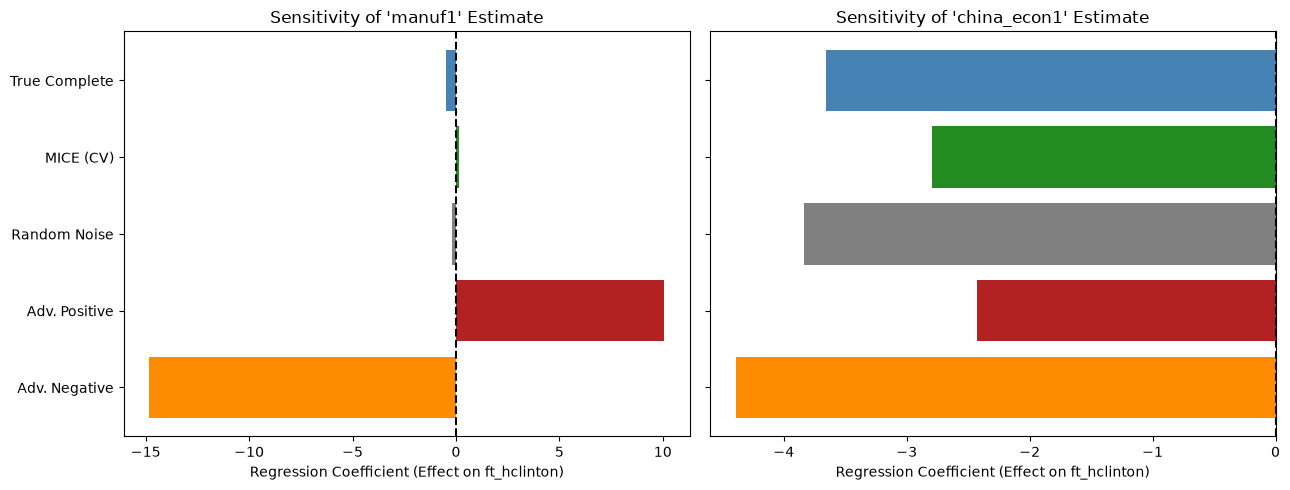

In [3]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

# Set random seed for reproducibility
np.random.seed(42)

# ==============================================================================
# 1. DOWNLOAD & PRE-PROCESS DATA (Translating Sections 2.1 - 2.3)
# ==============================================================================
data_dir = "../data"
os.makedirs(data_dir, exist_ok=True)

urls = {
    "anesimputation.dta": "http://static.lib.virginia.edu/statlab/materials/data/anesimputation.dta",
    "anesocc.csv": "http://static.lib.virginia.edu/statlab/materials/data/anesocc.csv",
    "ma.dta": "http://static.lib.virginia.edu/statlab/materials/data/ma.dta",
}

for fname, url in urls.items():
    fpath = os.path.join(data_dir, fname)
    if not os.path.exists(fpath):
        urllib.request.urlretrieve(url, fpath)

# Import ANES dataset (convert_categoricals=False matches R's convert.factors=FALSE)
anesimp = pd.read_stata(os.path.join(data_dir, "anesimputation.dta"), convert_categoricals=False)

# Select only numeric columns before checking for values < 0
numeric_cols = anesimp.select_dtypes(include=[np.number]).columns

# Code values < 0 as missing (NaN) only in numeric columns
anesimp[numeric_cols] = anesimp[numeric_cols].mask(anesimp[numeric_cols] < 0, np.nan)

# Import occupation data (handling encoding issues like iconv in R)
anesocc = pd.read_csv(
    os.path.join(data_dir, "anesocc.csv"),
    sep=";",
    na_values=["", "NA"],
    encoding="latin1"
)[["caseid", "dem_occnow", "dem_indnow"]]

# Create dichotomous manufacturing indicator ('manuf')
occ_str = anesocc["dem_occnow"].astype(str)
ind_str = anesocc["dem_indnow"].astype(str)

cond_manu = (
    (occ_str.str.contains("manu", case=False, na=False) & ~occ_str.str.contains("manuver", case=False, na=False))
    | ind_str.str.contains("manu", case=False, na=False)
)
cond_na = anesocc["dem_occnow"].isna() | anesocc["dem_indnow"].isna()

anesimp["manuf"] = np.where(cond_manu, 1.0, np.where(cond_na, np.nan, 0.0))

# Merge Mergers & Acquisitions (M&A) data
maimp = pd.read_stata(os.path.join(data_dir, "ma.dta"), convert_categoricals=False)
anesimp = pd.merge(anesimp, maimp, on="sample_state", how="inner")

# Recode variables to match R car::recode specifications
anesimp["patriot_amident"] = anesimp["patriot_amident"].replace({5: 0, 4: 1, 3: 2, 2: 3, 1: 4})
anesimp["econ_ecnext_x"]   = anesimp["econ_ecnext_x"].replace({1: 0, 2: 1, 3: 2, 4: 3, 5: 4})
anesimp["pid_x"]           = anesimp["pid_x"].replace({1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6})
anesimp["dem_edugroup_x"]  = anesimp["dem_edugroup_x"].replace({1: 0, 2: 1, 3: 2, 4: 3, 5: 4})

# Drop problematic / high-missingness columns
drop_cols = [
    "interest_whovote2008", "prevote_primvwho", "prevote_intpresst",
    "relig_ident_1st", "iwrobspre_skintone", "iwrobspre_levinfo",
    "iwrobspre_intell", "iwrobspre_interest", "gayrt_discrev_x", "Statename"
]
anesimp = anesimp.drop(columns=[c for c in drop_cols if c in anesimp.columns])

# Prepare regression dataframe (anesimpor)
anesimpor = anesimp.copy()
anesimpor["china_econ"] = anesimpor["china_econ"].replace({1: 0, 3: 0, 2: 1})
anesimpor["LogMANO"]    = np.log(anesimpor["MANo"] + 1.01)

# Fit Complete-Case OLS Regression
formula = "ft_hclinton ~ C(manuf) + pid_x + patriot_amident + C(china_econ) + LogMANO"
fitols_clean = smf.ols(formula, data=anesimpor).fit()


# ==============================================================================
# 2. MULTIPLE IMPUTATION & POOLING HELPER (MICE Equivalent in Python)
# ==============================================================================
# Exclude variables set to 0 in R's predictorMatrix
exclude_from_pred = [
    "sample_state", "Total_mil", "PriOwn_mil", "GovValue_mil",
    "PriOwn", "GovOwn", "MANo", "manuf"
]

def run_mice_and_pool(df_input, m=5, maxit=5):
    """
    Runs MICE (IterativeImputer) m times with posterior sampling and pools
    OLS regression estimates using Rubin's Rules.
    """
    num_cols = df_input.select_dtypes(include=[np.number]).columns.tolist()
    pred_cols = [c for c in num_cols if c not in exclude_from_pred]
    
    # Ensure our target regression variables are included in the imputation matrix
    target_vars = ["ft_hclinton", "manuf", "pid_x", "patriot_amident", "china_econ"]
    imp_cols = list(dict.fromkeys(pred_cols + [c for c in target_vars if c in df_input.columns]))

    imputed_dfs = []
    models = []

    for i in range(m):
        imputer = IterativeImputer(
            estimator=BayesianRidge(),
            sample_posterior=True,
            max_iter=maxit,
            random_state=100 + i
        )
        df_imp = df_input.copy()
        df_imp[imp_cols] = imputer.fit_transform(df_input[imp_cols])

        # Post-process categorical/ordinal bounds to match discrete factor levels
        df_imp["manuf"]           = np.clip(np.round(df_imp["manuf"]), 0, 1)
        df_imp["china_econ"]      = np.clip(np.round(df_imp["china_econ"]), 1, 3).replace({1: 0, 3: 0, 2: 1})
        df_imp["patriot_amident"] = np.clip(np.round(df_imp["patriot_amident"]), 0, 4)
        df_imp["pid_x"]           = np.clip(np.round(df_imp["pid_x"]), 0, 6)
        df_imp["LogMANO"]         = np.log(df_imp["MANo"] + 1.01)

        imputed_dfs.append(df_imp)
        models.append(smf.ols(formula, data=df_imp).fit())

    # Pool coefficients using Rubin's Rules (mean across m imputations)
    pooled_params = pd.concat([mod.params for mod in models], axis=1).mean(axis=1)
    return imputed_dfs, pooled_params


# ==============================================================================
# 3. EXPERIMENT A: CROSS-VALIDATION VIA ARTIFICIAL MASKING (AMPUTATION)
# ==============================================================================
vars_clean = ["ft_hclinton", "manuf", "pid_x", "patriot_amident", "china_econ", "LogMANO"]
complete_mask = anesimpor[vars_clean].notna().all(axis=1)

cv_data_raw = anesimp.loc[complete_mask].reset_index(drop=True)
cv_truth    = anesimpor.loc[complete_mask].reset_index(drop=True)

# Ground truth OLS fit on complete subset
fit_truth = smf.ols(formula, data=cv_truth).fit()

# Mask 20% of observed values in key predictors (MCAR amputation)
n_cv = len(cv_data_raw)
mask_size = int(round(0.20 * n_cv))

mask_manuf   = np.random.choice(n_cv, size=mask_size, replace=False)
mask_china   = np.random.choice(n_cv, size=mask_size, replace=False)
mask_patriot = np.random.choice(n_cv, size=mask_size, replace=False)
mask_pid     = np.random.choice(n_cv, size=mask_size, replace=False)

cv_masked = cv_data_raw.copy()
cv_masked.loc[mask_manuf, "manuf"]             = np.nan
cv_masked.loc[mask_china, "china_econ"]        = np.nan
cv_masked.loc[mask_patriot, "patriot_amident"] = np.nan
cv_masked.loc[mask_pid, "pid_x"]               = np.nan

# Run MICE on masked dataset
cv_imputed_dfs, pool_cv_params = run_mice_and_pool(cv_masked, m=5, maxit=5)

# Evaluate Point-Level Reconstruction Accuracy across the 5 imputed datasets
acc_manuf, acc_china, rmse_patriot, rmse_pid = [], [], [], []

for df_m in cv_imputed_dfs:
    acc_manuf.append(np.mean(df_m.loc[mask_manuf, "manuf"] == cv_truth.loc[mask_manuf, "manuf"]))
    acc_china.append(np.mean(df_m.loc[mask_china, "china_econ"] == cv_truth.loc[mask_china, "china_econ"]))
    rmse_patriot.append(np.sqrt(np.mean((df_m.loc[mask_patriot, "patriot_amident"] - cv_truth.loc[mask_patriot, "patriot_amident"]) ** 2)))
    rmse_pid.append(np.sqrt(np.mean((df_m.loc[mask_pid, "pid_x"] - cv_truth.loc[mask_pid, "pid_x"]) ** 2)))

print("=== Experiment A: CV Imputation Reconstruction Performance ===")
print(f"manuf Accuracy (Baseline Mode = {(cv_truth['manuf'] == 0).mean():.3f}): Mean = {np.mean(acc_manuf):.3f} (SD = {np.std(acc_manuf):.3f})")
print(f"china_econ Accuracy:                     Mean = {np.mean(acc_china):.3f} (SD = {np.std(acc_china):.3f})")
print(f"patriot_amident RMSE (0-4 scale):        Mean = {np.mean(rmse_patriot):.3f} (SD = {np.std(rmse_patriot):.3f})")
print(f"pid_x RMSE (0-6 scale):                  Mean = {np.mean(rmse_pid):.3f} (SD = {np.std(rmse_pid):.3f})\n")


# ==============================================================================
# 4. EXPERIMENT B: ADVERSARIAL / NMAR SENSITIVITY ANALYSIS
# ==============================================================================
adv_pos   = anesimpor.copy()
adv_neg   = anesimpor.copy()
adv_noise = anesimpor.copy()

na_manuf = anesimpor["manuf"].isna()
na_china = anesimpor["china_econ"].isna()

# 1. Adversarial Positive Bias: Missing workers with high Clinton sentiment (>50) are set to 1
adv_pos.loc[na_manuf, "manuf"] = np.where(adv_pos.loc[na_manuf, "ft_hclinton"] > 50, 1.0, 0.0)
adv_pos.loc[na_china, "china_econ"] = np.where(adv_pos.loc[na_china, "ft_hclinton"] > 50, 1.0, 0.0)

# 2. Adversarial Negative Bias: Missing workers with low Clinton sentiment (<=50) are set to 1
adv_neg.loc[na_manuf, "manuf"] = np.where(adv_neg.loc[na_manuf, "ft_hclinton"] <= 50, 1.0, 0.0)
adv_neg.loc[na_china, "china_econ"] = np.where(adv_neg.loc[na_china, "ft_hclinton"] <= 50, 1.0, 0.0)

# 3. Random Noise Imputation: Sample unconditionally with replacement from observed values
adv_noise.loc[na_manuf, "manuf"] = np.random.choice(
    anesimpor["manuf"].dropna(), size=na_manuf.sum(), replace=True
)
adv_noise.loc[na_china, "china_econ"] = np.random.choice(
    anesimpor["china_econ"].dropna(), size=na_china.sum(), replace=True
)

# Fit OLS models across adversarial regimes
fit_adv_pos   = smf.ols(formula, data=adv_pos).fit()
fit_adv_neg   = smf.ols(formula, data=adv_neg).fit()
fit_adv_noise = smf.ols(formula, data=adv_noise).fit()

# Combine all coefficient estimates for comparison
coef_comparison = pd.DataFrame({
    "OLS_Complete": fit_truth.params,
    "CV_Imputed":   pool_cv_params,
    "Adv_Noise":    fit_adv_noise.params,
    "Adv_Positive": fit_adv_pos.params,
    "Adv_Negative": fit_adv_neg.params
})
print("=== Coefficient Comparison Across Imputation Regimes ===")
print(coef_comparison.round(3))


# ==============================================================================
# 5. APPENDIX FIGURE: COEFFICIENT STABILITY ACROSS IMPUTATION REGIMES
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

regimes = ["True Complete", "MICE (CV)", "Random Noise", "Adv. Positive", "Adv. Negative"]
colors  = ["steelblue", "forestgreen", "gray", "firebrick", "darkorange"]

# Plot 1: Manufacturing Coefficient (C(manuf)[T.1.0])
manuf_vals = coef_comparison.loc["C(manuf)[T.1.0]"].values
axes[0].barh(regimes, manuf_vals, color=colors)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[0].set_title("Sensitivity of 'manuf1' Estimate")
axes[0].set_xlabel("Regression Coefficient (Effect on ft_hclinton)")
axes[0].invert_yaxis()  # Match R barplot top-to-bottom order

# Plot 2: China Economic View Coefficient (C(china_econ)[T.1.0])
china_vals = coef_comparison.loc["C(china_econ)[T.1.0]"].values
axes[1].barh(regimes, china_vals, color=colors)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Sensitivity of 'china_econ1' Estimate")
axes[1].set_xlabel("Regression Coefficient (Effect on ft_hclinton)")

plt.tight_layout()
plt.show()